# 7 · DE CUDA, version 2 : un bloc par individu, un thread par gène

La version 1 n'occupe que quelques multiprocesseurs du GPU, car elle n'a qu'un thread par individu. La
version 2 change le découpage : chaque individu est traité par un bloc, et chaque thread du bloc s'occupe
d'un gène. Le code est dans `src/cuda/de_cuda_v2.cu`.

| | v1 | v2 |
|---|---|---|
| Kernels par génération | 3 (mutation-croisement, évaluation, sélection) | **2** : kernel **P** (indices) + kernel fusionné **MCER** |
| Organisation | 1 thread par individu, boucle sur les D gènes | **1 bloc par individu**, 1 thread par gène |
| Accès mémoire | pas de D entre threads voisins (non coalescés) | gènes consécutifs entre threads voisins (**coalescés**) |
| Essai `trial` | tableau en mémoire globale | **mémoire partagée** du bloc |
| Évaluation f | 1 thread fait la boucle sur D | **réduction parallèle** dans le bloc (log₂ T étapes) |
| Remplacement | kernel séparé | dans MCER, écrit dans un **second tampon** (double tampon, puis échange des pointeurs) |
| Meilleur individu | N fitness copiées, min sur CPU | **argmin sur GPU**, 16 octets copiés |
| Threads par bloc | fixé (128) | **automatique** selon D, N et le nombre de SM (règle mesurée à la section 5) |

Le double tampon est indispensable : dans MCER, un bloc lit x_r1, x_r2, x_r3 pendant que d'autres blocs écrivent leur gagnant. Écrire dans le tableau qu'on lit créerait une race condition.

Dans ce notebook, nous mesurons l'occupation théorique du GPU selon la taille de bloc, nous contrôlons la
v2 sur les 4 fonctions, puis nous vérifions qu'elle donne la même qualité que la v1. Nous mesurons ensuite
le temps pour plusieurs tailles de bloc, ce qui a fixé la règle automatique, et nous comparons les temps
de la v1 et de la v2 selon D et N.

In [9]:
# Récupérer le projet.
# Si DE_CUDA.zip a été déposé dans Colab (icône dossier à gauche → Importer), on utilise ce dossier ;
# sinon on copie le dépôt public GitHub (aucun compte nécessaire).
import os
if os.path.exists("/content/DE_CUDA.zip") and not os.path.exists("/content/DE_CUDA/src"):
    !unzip -q -o /content/DE_CUDA.zip -d /content
if not os.path.exists("/content/DE_CUDA/src"):
    !git clone -q https://github.com/amenacer/DE_CUDA.git /content/DE_CUDA
%cd /content/DE_CUDA
!nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv

/content/DE_CUDA
name, driver_version, memory.total [MiB]
Tesla T4, 580.82.07, 15360 MiB


In [10]:
import subprocess, re, statistics as st, os, json
ROOT = "/content/DE_CUDA"
RAPPORT = []                       # tout ce qui est affiche est aussi garde pour le rapport
def note(s=""):
    print(s); RAPPORT.append(str(s))

def run(args, cwd=ROOT, ok_codes=(0,)):
    p = subprocess.run(args, cwd=cwd, capture_output=True, text=True)
    if p.returncode not in ok_codes:
        print(p.stdout); print(p.stderr)
        raise RuntimeError(f"{args[0]} a renvoye {p.returncode}")
    return p

def compile_cuda(src, out):
    p = run(["nvcc", "-O3", "-arch=sm_75", "-Xcompiler", "-Wall", "-Xcompiler", "-Wextra",
             "-o", out, src], cwd=f"{ROOT}/src/cuda")
    warn = (p.stdout + p.stderr).strip()
    note(f"{src} : " + ("compilation SANS aucun warning" if not warn else "WARNINGS :\n" + warn))

KV = re.compile(r"(\w+)=(\S+)")
def lance(prog, f, D, N, seed, csv=None, extra=()):
    """Lance un run et renvoie le dictionnaire de sa derniere ligne (best_error, time_s, ...)."""
    args = [prog, f, str(D), str(N), str(seed)] + ([csv] if csv else []) + list(extra)
    out = run(args).stdout.strip().splitlines()[-1]
    d = dict(KV.findall(out))
    for k in ("best_error", "time_s"):
        d[k] = float(d[k])
    return d

def mann_whitney(a, b):
    """p-valeur du test de Mann-Whitney bilateral ; 1.0 si les deux series sont identiques et constantes."""
    from scipy.stats import mannwhitneyu
    if len(set(a) | set(b)) == 1:
        return 1.0
    return float(mannwhitneyu(a, b, alternative="two-sided").pvalue)

def tableau_md(lignes, entetes):
    s = "| " + " | ".join(entetes) + " |\n|" + "---|" * len(entetes) + "\n"
    for l in lignes:
        s += "| " + " | ".join(str(x) for x in l) + " |\n"
    return s
print("outils prets")

outils prets


## 1. Compiler les deux versions

In [11]:
compile_cuda("de_cuda_v1.cu", "de_cuda_v1")
compile_cuda("de_cuda_v2.cu", "de_cuda_v2")
V1, V2 = f"{ROOT}/src/cuda/de_cuda_v1", f"{ROOT}/src/cuda/de_cuda_v2"

de_cuda_v1.cu : compilation SANS aucun warning
de_cuda_v2.cu : compilation SANS aucun warning


## 2. Occupation théorique selon la taille de bloc

`cudaOccupancyMaxActiveBlocksPerMultiprocessor` donne, pour chaque taille de bloc, combien de blocs tiennent en même temps sur un SM (limité par les registres et la mémoire partagée). « threads utiles » = part des threads qui ont un gène à traiter.

In [12]:
import io, csv
rows = []
for D in (10, 50, 100):
    out = run([V2, "--occupation", str(D)]).stdout.strip().splitlines()
    note("\n".join(out[:2]))
    for r in csv.DictReader(io.StringIO("\n".join(out[2:]))):
        r = {"D": D, **r}; rows.append(r)
with open(f"{ROOT}/results/occupation_v2.csv", "w", newline="") as fp:
    w = csv.DictWriter(fp, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)
note(tableau_md([[r["D"], r["threads/bloc"], r["shmem_octets"], r["blocs_par_SM"], r["occupation_%"], r["threads_utiles_%"]] for r in rows],
                ["D", "threads/bloc", "shmem (octets)", "blocs/SM", "occupation (%)", "threads utiles (%)"]))

GPU : Tesla T4, 40 SM, 1024 threads max par SM, 49152 octets de memoire partagee par bloc
Kernel k_MCER, D = 10 (choix automatique : 32 threads si N < 160, 32 threads sinon)
GPU : Tesla T4, 40 SM, 1024 threads max par SM, 49152 octets de memoire partagee par bloc
Kernel k_MCER, D = 50 (choix automatique : 64 threads si N < 160, 32 threads sinon)
GPU : Tesla T4, 40 SM, 1024 threads max par SM, 49152 octets de memoire partagee par bloc
Kernel k_MCER, D = 100 (choix automatique : 64 threads si N < 160, 32 threads sinon)
| D | threads/bloc | shmem (octets) | blocs/SM | occupation (%) | threads utiles (%) |
|---|---|---|---|---|---|
| 10 | 32 | 592 | 16 | 50.0 | 31.2 |
| 10 | 64 | 1104 | 16 | 100.0 | 15.6 |
| 10 | 128 | 2128 | 8 | 100.0 | 7.8 |
| 10 | 256 | 4176 | 4 | 100.0 | 3.9 |
| 10 | 512 | 8272 | 2 | 100.0 | 2.0 |
| 50 | 32 | 912 | 16 | 50.0 | 100.0 |
| 50 | 64 | 1424 | 16 | 100.0 | 78.1 |
| 50 | 128 | 2448 | 8 | 100.0 | 39.1 |
| 50 | 256 | 4496 | 4 | 100.0 | 19.5 |
| 50 | 512 | 8592 |

## 3. Contrôles de la v2 : 4 fonctions × D = 10, 50, 100

Chaque run vérifie lui-même que l'argmin GPU = min calculé sur CPU et que f(meilleur) par réduction parallèle = `evaluate()` du CPU. `sante=OK` sinon le run échoue. On vérifie aussi le déterminisme.

In [13]:
lignes = []
for f in ["sphere", "rosenbrock", "griewank", "rastrigin"]:
    for D in (10, 50, 100):
        r = lance(V2, f, D, 100, 1)
        lignes.append([f, D, r["threads"], f"{r['best_error']:.3e}", r["FE"], f"{r['time_s']:.4f}", r["sante"]])
note(tableau_md(lignes, ["fonction", "D", "threads/bloc", "best_error", "FE", "temps (s)", "sante"]))
a = lance(V2, "rastrigin", 50, 100, 3); b = lance(V2, "rastrigin", 50, 100, 3)
note(f"Determinisme v2 (rastrigin D=50 N=100 seed 3) : {a['best_error']:.15e} / {b['best_error']:.15e} -> "
     + ("IDENTIQUES" if a["best_error"] == b["best_error"] else "DIFFERENTS"))

| fonction | D | threads/bloc | best_error | FE | temps (s) | sante |
|---|---|---|---|---|---|---|
| sphere | 10 | 32 | 0.000e+00 | 100000 | 0.0080 | OK |
| sphere | 50 | 64 | 0.000e+00 | 500000 | 0.0435 | OK |
| sphere | 100 | 64 | 4.930e-32 | 1000000 | 0.0972 | OK |
| rosenbrock | 10 | 32 | 6.259e-01 | 100000 | 0.0083 | OK |
| rosenbrock | 50 | 64 | 4.114e+01 | 500000 | 0.0464 | OK |
| rosenbrock | 100 | 64 | 8.978e+01 | 1000000 | 0.1082 | OK |
| griewank | 10 | 32 | 0.000e+00 | 100000 | 0.0097 | OK |
| griewank | 50 | 64 | 0.000e+00 | 500000 | 0.0583 | OK |
| griewank | 100 | 64 | 0.000e+00 | 1000000 | 0.1557 | OK |
| rastrigin | 10 | 32 | 0.000e+00 | 100000 | 0.0088 | OK |
| rastrigin | 50 | 64 | 1.536e+02 | 500000 | 0.0505 | OK |
| rastrigin | 100 | 64 | 5.356e+02 | 1000000 | 0.1250 | OK |

Determinisme v2 (rastrigin D=50 N=100 seed 3) : 1.631731634000000e+02 / 1.631731634000000e+02 -> IDENTIQUES


## 4. Même qualité que la v1 ?

Test de Mann-Whitney, 4 fonctions, D = 10, N = 50, 10 runs.

In [14]:
CSV_Q = f"{ROOT}/results/qualite_v1_vs_v2.csv"
if os.path.exists(CSV_Q): os.remove(CSV_Q)
lignes = []
for f in ["sphere", "rosenbrock", "griewank", "rastrigin"]:
    e1 = [lance(V1, f, 10, 50, s, CSV_Q)["best_error"] for s in range(1, 11)]
    e2 = [lance(V2, f, 10, 50, s, CSV_Q)["best_error"] for s in range(1, 11)]
    p = mann_whitney(e1, e2)
    lignes.append([f, f"{st.mean(e1):.3e} ± {st.pstdev(e1):.2e}", f"{st.mean(e2):.3e} ± {st.pstdev(e2):.2e}",
                   f"{p:.3f}", "meme qualite" if p > 0.05 else "difference"])
note("Qualite v1 contre v2 (D = 10, N = 50, 10 runs, moyenne ± ecart-type de l'erreur)")
note(tableau_md(lignes, ["fonction", "v1", "v2", "p (Mann-Whitney)", "conclusion (p > 0,05)"]))

Qualite v1 contre v2 (D = 10, N = 50, 10 runs, moyenne ± ecart-type de l'erreur)
| fonction | v1 | v2 | p (Mann-Whitney) | conclusion (p > 0,05) |
|---|---|---|---|---|
| sphere | 0.000e+00 ± 0.00e+00 | 0.000e+00 ± 0.00e+00 | 1.000 | meme qualite |
| rosenbrock | 7.206e-01 ± 1.05e+00 | 4.633e-01 ± 5.09e-01 | 0.623 | meme qualite |
| griewank | 0.000e+00 ± 0.00e+00 | 0.000e+00 ± 0.00e+00 | 1.000 | meme qualite |
| rastrigin | 0.000e+00 ± 0.00e+00 | 0.000e+00 ± 0.00e+00 | 1.000 | meme qualite |



## 5. Même qualité en D = 50 ?

En D = 10, Sphere, Griewank et Rastrigin sont résolues exactement par les deux versions : le test ne dit rien sur ces trois fonctions. On compare donc aussi v1 et v2 en D = 50, où l'erreur n'est pas nulle (Rosenbrock et Rastrigin, N = 50, 10 runs). Avec 10 runs, « pas de différence significative » ne prouve pas que les deux versions sont équivalentes : cela signifie seulement qu'aucune différence n'est détectée.

In [15]:
CSV_Q2 = f"{ROOT}/results/qualite_v1_vs_v2_D50.csv"
if os.path.exists(CSV_Q2): os.remove(CSV_Q2)
lignes = []
for f in ["rosenbrock", "rastrigin"]:
    e1 = [lance(V1, f, 50, 50, s, CSV_Q2)["best_error"] for s in range(1, 11)]
    e2 = [lance(V2, f, 50, 50, s, CSV_Q2)["best_error"] for s in range(1, 11)]
    p = mann_whitney(e1, e2)
    lignes.append([f, f"{st.mean(e1):.3e} ± {st.pstdev(e1):.2e}", f"{st.median(e1):.3e}", f"{st.mean(e2):.3e} ± {st.pstdev(e2):.2e}", f"{st.median(e2):.3e}", f"{p:.3f}", "pas de difference" if p > 0.05 else "difference significative"])
note("Qualite v1 contre v2 (D = 50, N = 50, 10 runs)")
note(tableau_md(lignes, ["fonction", "v1 moyenne ± ET", "v1 mediane", "v2 moyenne ± ET", "v2 mediane", "p (Mann-Whitney)", "conclusion (5 %)"]))

Qualite v1 contre v2 (D = 50, N = 50, 10 runs)
| fonction | v1 moyenne ± ET | v1 mediane | v2 moyenne ± ET | v2 mediane | p (Mann-Whitney) | conclusion (5 %) |
|---|---|---|---|---|---|---|
| rosenbrock | 3.920e+01 ± 1.26e+00 | 3.973e+01 | 3.951e+01 ± 1.29e+00 | 3.997e+01 | 0.345 | pas de difference |
| rastrigin | 1.456e+02 ± 6.56e+00 | 1.459e+02 | 1.388e+02 ± 7.42e+00 | 1.412e+02 | 0.104 | pas de difference |



## 6. Quelle taille de bloc ?

Balayage mesuré : Rastrigin et Sphere, D = 50 / 100, N = 50 / 100 / 500, T = 32 à 256 threads par bloc, 3 runs. C'est ce balayage qui a fixé la règle automatique de `threads_auto` : **32 threads si D ≤ 32 ou si N ≥ 4 × (nombre de SM)**, sinon **64**. Sur le T4 (40 SM), le seuil est N = 160.

Pourquoi : avec peu d'individus (N = 50 ou 100 blocs pour 40 SM), le GPU n'est pas rempli et des blocs de 64 threads apportent plus de parallélisme ; avec N = 500, le GPU est déjà rempli et des blocs de 32 threads coûtent moins en `__syncthreads` et en étapes de réduction. Les blocs de 128 ou 256 threads sont toujours plus lents que le meilleur choix entre 32 et 64, bien que leur occupation théorique soit de 100 % : l'occupation n'est pas le seul critère.

Limites : la règle a été ajustée sur ces 12 cas (elle les reproduit donc par construction) ; le seuil N = 160 est seulement situé entre 100 et 500, les deux tailles mesurées ; la branche D ≤ 32 n'a pas été balayée (en D = 10, 32 threads est déjà le plus petit bloc possible et 22 threads sur 32 n'ont rien à faire).

In [16]:
CSV_T = f"{ROOT}/results/taille_bloc_v2.csv"
SW = {}
with open(CSV_T, "w") as fp:
    fp.write("algo,func,D,N,threads,seed,best_error,time_s,FE\n")
    for f in ("rastrigin", "sphere"):
        for D in (50, 100):
            for N in (50, 100, 500):
                for T in (32, 64, 128, 256):
                    t = []
                    for s in (1, 2, 3):
                        r = lance(V2, f, D, N, s, None, ["--threads", str(T)])
                        fp.write(f"cuda_v2,{f},{D},{N},{T},{s},{r['best_error']:.6e},{r['time_s']:.6f},{r['FE']}\n")
                        t.append(r["time_s"])
                    SW[(f, D, N, T)] = st.mean(t)
                SW[(f, D, N, "auto")] = st.mean([lance(V2, f, D, N, s)["time_s"] for s in (1, 2, 3)])
lignes = []
for f in ("rastrigin", "sphere"):
    for D in (50, 100):
        for N in (50, 100, 500):
            meilleur = min((32, 64, 128, 256), key=lambda T: SW[(f, D, N, T)])
            lignes.append([f, D, N] + [f"{SW[(f, D, N, T)]:.4f}" for T in (32, 64, 128, 256)]
                          + [meilleur, f"{SW[(f, D, N, 'auto')]:.4f}"])
note("Temps moyen (s) de la v2 selon le nombre de threads par bloc (3 runs)")
note(tableau_md(lignes, ["fonction", "D", "N", "T=32", "T=64", "T=128", "T=256", "meilleur T", "auto (s)"]))

Temps moyen (s) de la v2 selon le nombre de threads par bloc (3 runs)
| fonction | D | N | T=32 | T=64 | T=128 | T=256 | meilleur T | auto (s) |
|---|---|---|---|---|---|---|---|---|
| rastrigin | 50 | 50 | 0.1037 | 0.0912 | 0.1002 | 0.1263 | 64 | 0.0915 |
| rastrigin | 50 | 100 | 0.0536 | 0.0504 | 0.0588 | 0.0787 | 64 | 0.0504 |
| rastrigin | 50 | 500 | 0.0201 | 0.0222 | 0.0384 | 0.0825 | 32 | 0.0202 |
| rastrigin | 100 | 50 | 0.2752 | 0.2196 | 0.2238 | 0.2709 | 64 | 0.2196 |
| rastrigin | 100 | 100 | 0.1424 | 0.1250 | 0.1374 | 0.1766 | 64 | 0.1251 |
| rastrigin | 100 | 500 | 0.0601 | 0.0672 | 0.1081 | 0.1754 | 32 | 0.0602 |
| sphere | 50 | 50 | 0.0876 | 0.0811 | 0.0907 | 0.1176 | 64 | 0.0809 |
| sphere | 50 | 100 | 0.0449 | 0.0437 | 0.0517 | 0.0739 | 64 | 0.0438 |
| sphere | 50 | 500 | 0.0141 | 0.0179 | 0.0351 | 0.0813 | 32 | 0.0141 |
| sphere | 100 | 50 | 0.2159 | 0.1802 | 0.1852 | 0.2385 | 64 | 0.1810 |
| sphere | 100 | 100 | 0.1110 | 0.0965 | 0.1119 | 0.1532 | 64 | 0.0965 |
| sphe

## 7. Temps v1 contre v2 selon N et D

Rastrigin, N = 50 / 100 / 500, D = 10 / 50 / 100, 3 runs chacun.

In [17]:
CSV_TV = f"{ROOT}/results/temps_v1_v2.csv"
if os.path.exists(CSV_TV): os.remove(CSV_TV)
TT = {}
lignes = []
for D in (10, 50, 100):
    for N in (50, 100, 500):
        t1 = [lance(V1, "rastrigin", D, N, s, CSV_TV)["time_s"] for s in (1, 2, 3)]
        t2 = [lance(V2, "rastrigin", D, N, s, CSV_TV)["time_s"] for s in (1, 2, 3)]
        TT[(D, N)] = (st.mean(t1), st.mean(t2))
        lignes.append([D, N, f"{st.mean(t1):.4f}", f"{st.mean(t2):.4f}", f"{st.mean(t1)/st.mean(t2):.2f}"])
note("Temps moyen (s), Rastrigin, 3 runs")
note(tableau_md(lignes, ["D", "N", "v1 (s)", "v2 (s)", "gain v1/v2"]))

Temps moyen (s), Rastrigin, 3 runs
| D | N | v1 (s) | v2 (s) | gain v1/v2 |
|---|---|---|---|---|
| 10 | 50 | 0.0436 | 0.0171 | 2.55 |
| 10 | 100 | 0.0261 | 0.0088 | 2.96 |
| 10 | 500 | 0.0054 | 0.0031 | 1.72 |
| 50 | 50 | 0.7630 | 0.0914 | 8.34 |
| 50 | 100 | 0.4819 | 0.0505 | 9.54 |
| 50 | 500 | 0.1017 | 0.0202 | 5.04 |
| 100 | 50 | 2.7907 | 0.2201 | 12.68 |
| 100 | 100 | 1.8383 | 0.1253 | 14.67 |
| 100 | 500 | 0.3880 | 0.0601 | 6.46 |



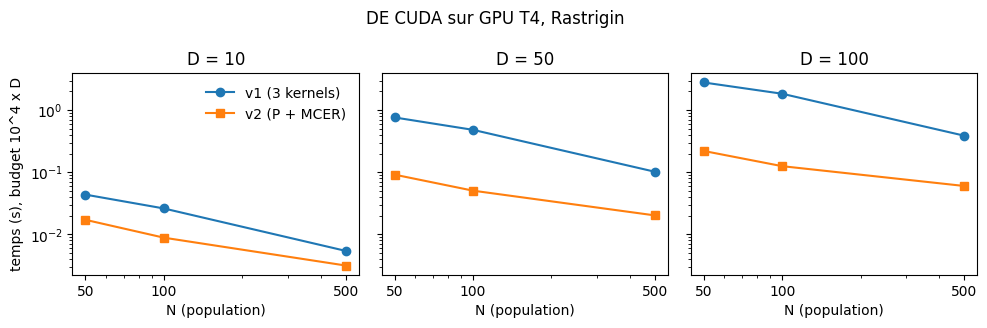

In [18]:
import matplotlib.pyplot as plt
os.makedirs(f"{ROOT}/figures", exist_ok=True)
Ns = [50, 100, 500]
fig, axs = plt.subplots(1, 3, figsize=(10, 3.3), sharey=True)
for ax, D in zip(axs, (10, 50, 100)):
    ax.plot(Ns, [TT[(D, N)][0] for N in Ns], "o-", label="v1 (3 kernels)")
    ax.plot(Ns, [TT[(D, N)][1] for N in Ns], "s-", label="v2 (P + MCER)")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(Ns, [str(n) for n in Ns])
    ax.set_title(f"D = {D}"); ax.set_xlabel("N (population)")
axs[0].set_ylabel("temps (s), budget 10^4 x D"); axs[0].legend(frameon=False)
fig.suptitle("DE CUDA sur GPU T4, Rastrigin"); fig.tight_layout()
fig.savefig(f"{ROOT}/figures/temps_v1_v2_N.png", dpi=200); plt.show()

## 8. Rapport

La dernière cellule enregistre les résultats ci-dessus dans `results/etape4_v2_resultats.md`.

In [19]:
os.makedirs(f"{ROOT}/results", exist_ok=True)
with open(f"{ROOT}/results/etape4_v2_resultats.md", "w") as fp:
    fp.write("# Étape 4 — DE CUDA v2 : occupation, qualité, temps\n\n")
    fp.write("GPU : " + run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"]).stdout.strip() + "\n\n")
    fp.write("```\n" + "\n".join(RAPPORT) + "\n```\n")